# Fixed-design PPO convergence

This notebook compares PPO convergence for five fixed PV and battery designs using training seeds 42--44. Shaded regions show one standard deviation across seeds.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUN_ROOT = Path("runs")
SEEDS = (42, 43, 44)
ROLLING_WINDOW = 25

In [2]:
design_directories = {
    "PV 6.6, battery 4.5": RUN_ROOT / "ppo_fixed_6.6_4.5_multiseed",
    "PV 4.0, battery 4.5": RUN_ROOT / "fixed_design_sweep/pv4_battery4p5",
    "PV 9.0, battery 4.5": RUN_ROOT / "fixed_design_sweep/pv9_battery4p5",
    "PV 6.6, battery 2.0": RUN_ROOT / "fixed_design_sweep/pv6p6_battery2",
    "PV 6.6, battery 8.0": RUN_ROOT / "fixed_design_sweep/pv6p6_battery8",
}
histories = []
final_results = []
for design, root in design_directories.items():
    for seed in SEEDS:
        directory = root / f"seed_{seed}"
        if not directory.is_dir():
            raise FileNotFoundError(directory)
        history = pd.read_csv(directory / "training.csv")
        history["design"] = design
        history["seed"] = seed
        history["training_smoothed"] = history["mean_cost_chf"].rolling(ROLLING_WINDOW, center=True, min_periods=ROLLING_WINDOW).mean()
        histories.append(history)
        with (directory / "validation.json").open() as file:
            final = json.load(file)
        final_results.append({"design": design, "seed": seed, "cost_chf": final["mean_cost_chf"]})
history = pd.concat(histories, ignore_index=True)
final_results = pd.DataFrame(final_results)

## Training convergence

A flat late-stage curve indicates that additional PPO updates are no longer reducing cost consistently.

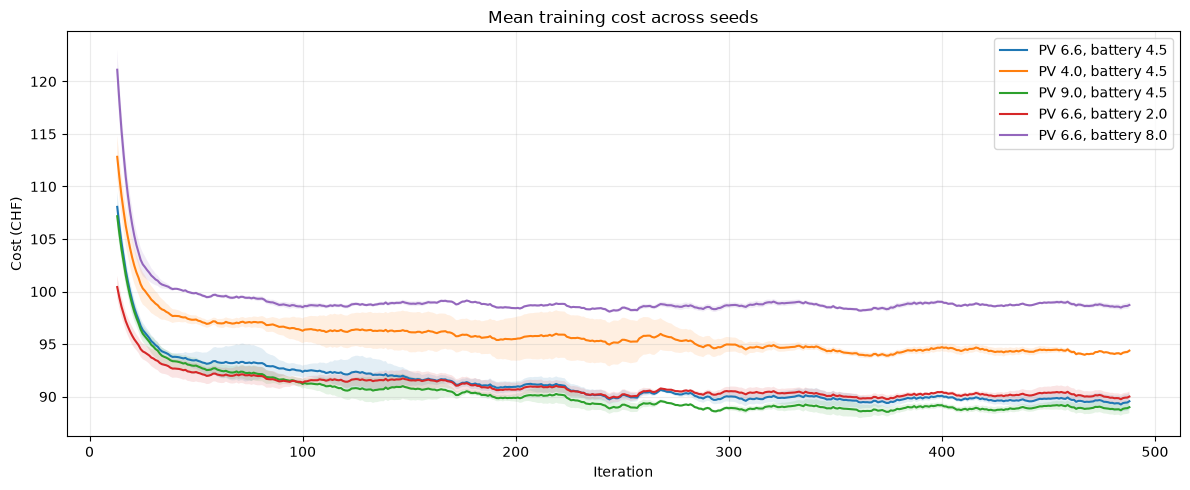

In [3]:
fig, axis = plt.subplots(figsize=(12, 5))
for design in design_directories:
    selected = history[history["design"] == design]
    curve = selected.groupby("iteration")["training_smoothed"].agg(["mean", "std"])
    axis.plot(curve.index, curve["mean"], label=design)
    axis.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], alpha=0.12)
axis.set(title="Mean training cost across seeds", xlabel="Iteration", ylabel="Cost (CHF)")
axis.grid(alpha=0.25)
axis.legend()
plt.tight_layout()

## Validation convergence

Only common 10-iteration checkpoints are shown so every design uses the same plotting frequency. Individual checkpoints remain noisy because their stochastic scenarios change.

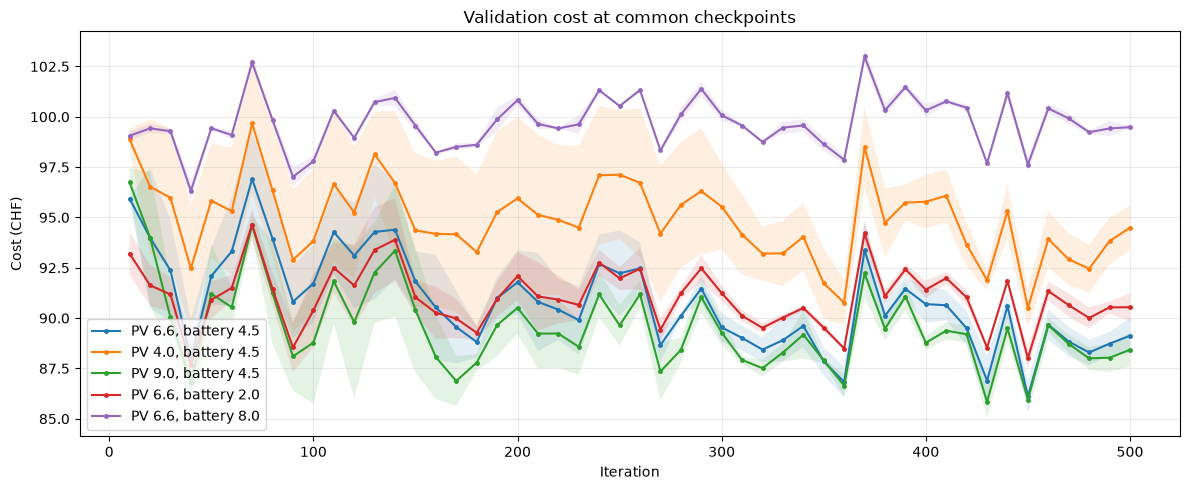

In [4]:
fig, axis = plt.subplots(figsize=(12, 5))
for design in design_directories:
    selected = history[(history["design"] == design) & (history["iteration"] % 10 == 0)].dropna(subset=["validation_mean_cost_chf"])
    curve = selected.groupby("iteration")["validation_mean_cost_chf"].agg(["mean", "std"])
    axis.plot(curve.index, curve["mean"], marker="o", markersize=2.5, label=design)
    axis.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], alpha=0.12)
axis.set(title="Validation cost at common checkpoints", xlabel="Iteration", ylabel="Cost (CHF)")
axis.grid(alpha=0.25)
axis.legend()
plt.tight_layout()

## Late-stage behaviour

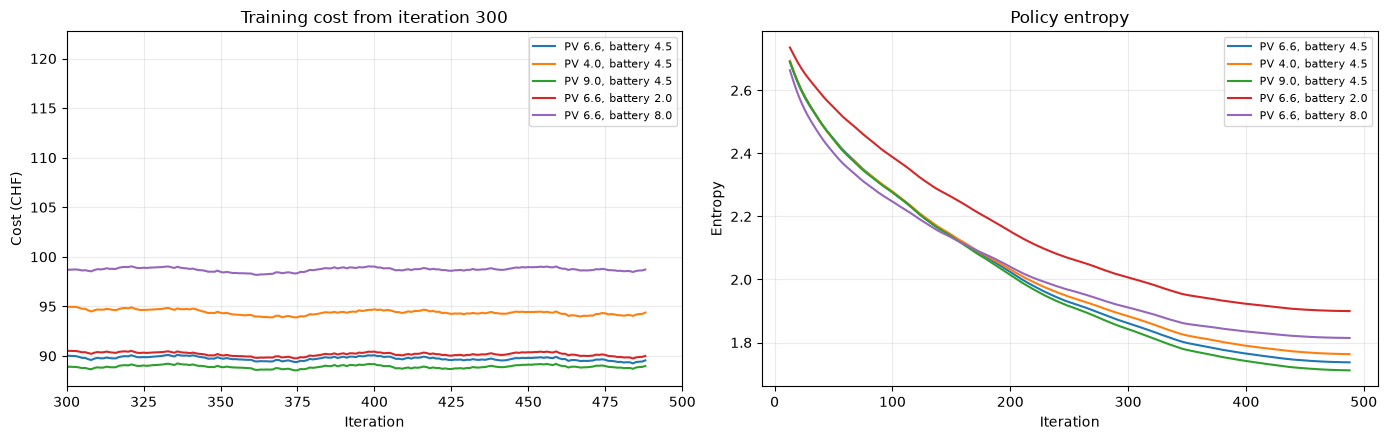

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for design in design_directories:
    selected = history[history["design"] == design]
    training_curve = selected.groupby("iteration")["training_smoothed"].mean()
    entropy_curve = selected.groupby("iteration")["action_entropy"].mean().rolling(25, center=True, min_periods=25).mean()
    axes[0].plot(training_curve.index, training_curve, label=design)
    axes[1].plot(entropy_curve.index, entropy_curve, label=design)
axes[0].set_xlim(300, 500)
axes[0].set(title="Training cost from iteration 300", xlabel="Iteration", ylabel="Cost (CHF)")
axes[1].set(title="Policy entropy", xlabel="Iteration", ylabel="Entropy")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.tight_layout()

## Convergence diagnostic and final cost

The diagnostic is transparent but not paper-derived: convergence requires the mean cost over iterations 401--500 to differ from iterations 301--400 by less than 0.25 CHF, with an absolute final-window slope below 0.01 CHF per iteration.

In [6]:
rows = []
for design in design_directories:
    aggregate = history[history["design"] == design].groupby("iteration")["mean_cost_chf"].mean().reset_index()
    previous_mean = aggregate[aggregate["iteration"].between(301, 400)]["mean_cost_chf"].mean()
    late = aggregate[aggregate["iteration"].between(401, 500)]
    late_mean = late["mean_cost_chf"].mean()
    late_change = late_mean - previous_mean
    late_slope = np.polyfit(late["iteration"], late["mean_cost_chf"], 1)[0]
    costs = final_results[final_results["design"] == design]["cost_chf"]
    rows.append({
        "design": design,
        "final cost mean (CHF)": costs.mean(),
        "seed std (CHF)": costs.std(),
        "late change (CHF)": late_change,
        "late slope (CHF/iteration)": late_slope,
        "converged": abs(late_change) < 0.25 and abs(late_slope) < 0.01,
    })
convergence = pd.DataFrame(rows).set_index("design").sort_values("final cost mean (CHF)")
convergence

,final cost mean (CHF),seed std (CHF),late change (CHF),late slope (CHF/iteration),converged
design,,,,,
"PV 9.0, battery 4.5",88.006365,0.619524,0.005209,-0.000353,True
"PV 6.6, battery 4.5",88.456071,0.814813,-0.125447,-0.005729,True
"PV 6.6, battery 2.0",90.089479,0.600785,-0.050980,-0.004524,True
"PV 4.0, battery 4.5",93.374581,1.052245,-0.097139,-0.004637,True
"PV 6.6, battery 8.0",99.154293,0.048704,0.061340,-0.002287,True


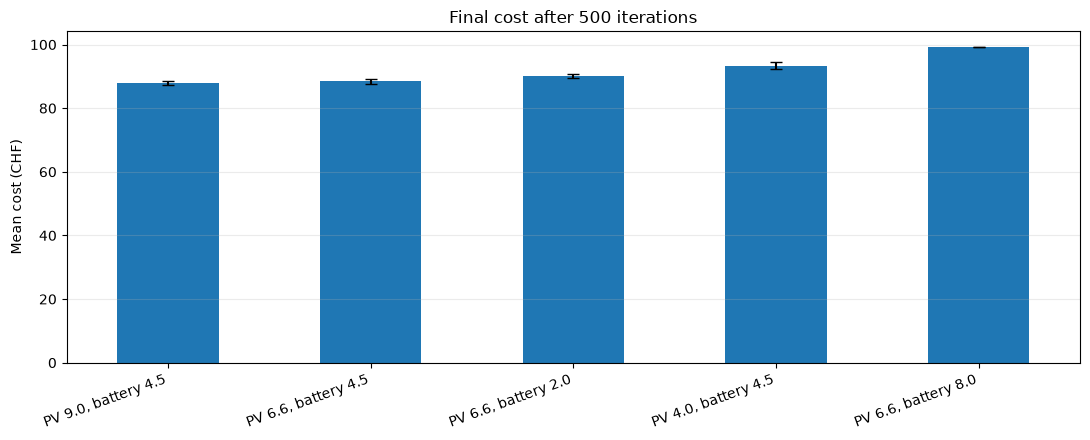

In [7]:
axis = convergence["final cost mean (CHF)"].plot.bar(
    yerr=convergence["seed std (CHF)"], figsize=(11, 4.5), capsize=4
)
axis.set(title="Final cost after 500 iterations", xlabel="", ylabel="Mean cost (CHF)")
axis.grid(axis="y", alpha=0.25)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

## Entropy coefficient ablation

This comparison keeps the design fixed at 6.6 kWp PV and 4.5 kWh battery and changes only PPO's entropy coefficient. The values 0.001 and 0.01 are experimental choices, not settings taken from either paper. All curves use training seeds 42--44.

In [8]:
entropy_directories = {
    "0": RUN_ROOT / "ppo_fixed_6.6_4.5_multiseed",
    "0.001": RUN_ROOT / "entropy_ablation/entropy_0p001",
    "0.01": RUN_ROOT / "entropy_ablation/entropy_0p01",
}
entropy_histories = []
entropy_final = []
for coefficient, root in entropy_directories.items():
    for seed in SEEDS:
        directory = root / f"seed_{seed}"
        run = pd.read_csv(directory / "training.csv")
        run["coefficient"] = coefficient
        run["seed"] = seed
        run["training_smoothed"] = run["mean_cost_chf"].rolling(ROLLING_WINDOW, center=True, min_periods=ROLLING_WINDOW).mean()
        entropy_histories.append(run)
        with (directory / "validation.json").open() as file:
            result = json.load(file)
        entropy_final.append({"coefficient": coefficient, "seed": seed, "cost_chf": result["mean_cost_chf"]})
entropy_history = pd.concat(entropy_histories, ignore_index=True)
entropy_final = pd.DataFrame(entropy_final)

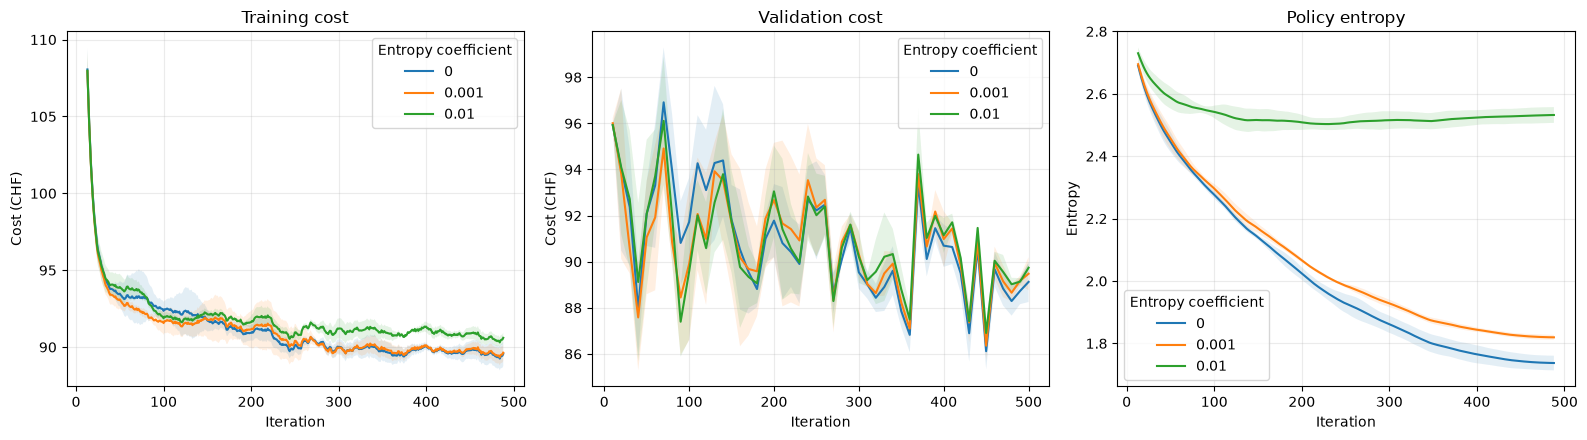

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for coefficient in entropy_directories:
    selected = entropy_history[entropy_history["coefficient"] == coefficient]
    training = selected.groupby("iteration")["training_smoothed"].agg(["mean", "std"])
    validation = selected[(selected["iteration"] % 10 == 0)].groupby("iteration")["validation_mean_cost_chf"].agg(["mean", "std"])
    policy_entropy = selected.groupby("iteration")["action_entropy"].agg(["mean", "std"]).rolling(25, center=True, min_periods=25).mean()
    for axis, curve in zip(axes, (training, validation, policy_entropy)):
        axis.plot(curve.index, curve["mean"], label=coefficient)
        axis.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], alpha=0.12)
axes[0].set(title="Training cost", xlabel="Iteration", ylabel="Cost (CHF)")
axes[1].set(title="Validation cost", xlabel="Iteration", ylabel="Cost (CHF)")
axes[2].set(title="Policy entropy", xlabel="Iteration", ylabel="Entropy")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(title="Entropy coefficient")
plt.tight_layout()

In [10]:
rows = []
for coefficient in entropy_directories:
    selected = entropy_history[entropy_history["coefficient"] == coefficient]
    final_costs = entropy_final[entropy_final["coefficient"] == coefficient].set_index("seed")["cost_chf"]
    late = selected[selected["iteration"].between(401, 500)]
    rows.append({
        "entropy coefficient": coefficient,
        "final cost mean (CHF)": final_costs.mean(),
        "seed std (CHF)": final_costs.std(),
        "difference from zero (CHF)": (final_costs - entropy_final[entropy_final["coefficient"] == "0"].set_index("seed")["cost_chf"]).mean(),
        "last-100 action entropy": late["action_entropy"].mean(),
        "last-100 training cost (CHF)": late["mean_cost_chf"].mean(),
        "battery saturation": late["battery_action_saturation"].mean(),
        "EV saturation": late["ev_action_saturation"].mean(),
    })
entropy_summary = pd.DataFrame(rows).set_index("entropy coefficient")
entropy_summary

,final cost mean (CHF),seed std (CHF),difference from zero (CHF),last-100 action entropy,last-100 training cost (CHF),battery saturation,EV saturation
entropy coefficient,,,,,,,
0,88.456071,0.814813,0.000000,1.745511,89.660042,0.297806,0.304421
0.001,88.856669,0.622198,0.400598,1.826833,89.730430,0.359582,0.381673
0.01,89.053354,0.172951,0.597283,2.528928,90.769889,0.536367,0.610255


### Interpretation

The entropy term changes the policy as intended, but it does not improve this fixed-design result. Mean final cost is 88.46 CHF with coefficient 0, 88.86 CHF with 0.001, and 89.05 CHF with 0.01. The strongest setting keeps substantially more action entropy but also raises late training cost and action saturation. With only three training seeds, this is evidence for retaining coefficient 0 in this setup, not a general claim that entropy regularisation is harmful.